# 04 Errors and limitations

Error analysis of the **frozen model** (`voting_ensemble`) on the saved test predictions, compared with persistence and hour-of-week. This notebook only **reads** `results/test_predictions.parquet`. Test data is used here to describe errors and to report; nothing here changes the model. The test run was not sealed (see the disclosure in notebook 03).

In [1]:
import json, os, sys
from pathlib import Path

# Work from the repository root whether the notebook is opened from notebooks/ or the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

import shutil
from evaluate import breakdown

tp = pd.read_parquet("results/test_predictions.parquet")
tp["day"] = tp["timestamp"].dt.date
tp["abs_err"] = (tp["target_2h"] - tp["pred"]).abs()
tp["rain"] = np.where(tp["precipitation"] > 0, "rain", "dry")
tp["period"] = np.where((tp["dow"] < 5) & tp["hour"].isin([7, 8, 9, 16, 17, 18]), "weekday rush (7-9, 16-18)", "off-peak")
fm = json.load(open("configs/final_model.json"))
print(fm["selected"], "|", len(tp), "test rows |", tp["timestamp"].min(), "to", tp["timestamp"].max())

voting_ensemble | 6872 test rows | 2017-05-26 03:00:00 to 2017-06-30 21:00:00


## 1. Error breakdowns
For each grouping: MAE of the model, of hour-of-week and of persistence (km/h), and skill against persistence, using `breakdown()` from `src/evaluate.py`.

In [2]:
def compare(by):
    a = breakdown(tp, by)                                   # model vs persistence
    b = breakdown(tp.assign(persist=tp["how"]), by)         # same function, hour-of-week as the "reference"
    out = pd.DataFrame({by: a[by], "n": a["n"], "MAE_model": a["MAE"], "MAE_hour_of_week": b["MAE_persistence"],
                        "MAE_persistence": a["MAE_persistence"], "skill_vs_persistence": a["skill"]})
    out["model_minus_how"] = out["MAE_model"] - out["MAE_hour_of_week"]
    return out.round(3)

tabs = {k: compare(k) for k in ["segment_id", "hour", "dow", "rain", "period"]}
for k, t in tabs.items():
    t.to_csv(f"results/errors_by_{k}.csv", index=False)
tabs["segment_id"]

,segment_id,n,MAE_model,MAE_hour_of_week,MAE_persistence,skill_vs_persistence,model_minus_how
0,400100,859,1.802,1.581,1.686,-0.068,0.221
1,400414,859,2.789,2.703,8.092,0.655,0.086
2,401507,859,2.416,2.008,5.333,0.547,0.408
3,402287,859,3.122,3.036,6.444,0.516,0.086
4,404554,859,2.958,2.798,5.958,0.503,0.161
5,407157,859,2.540,2.237,3.770,0.326,0.303
6,407176,859,2.761,3.051,4.738,0.417,-0.290
7,413878,859,2.076,2.074,4.041,0.486,0.001


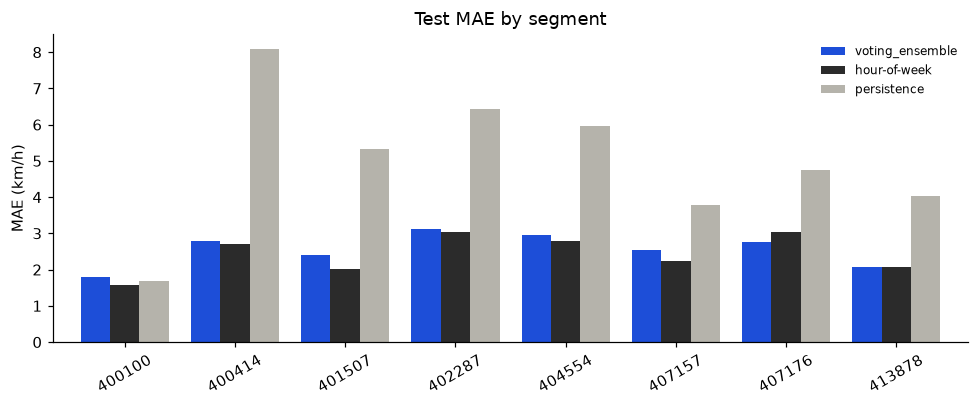

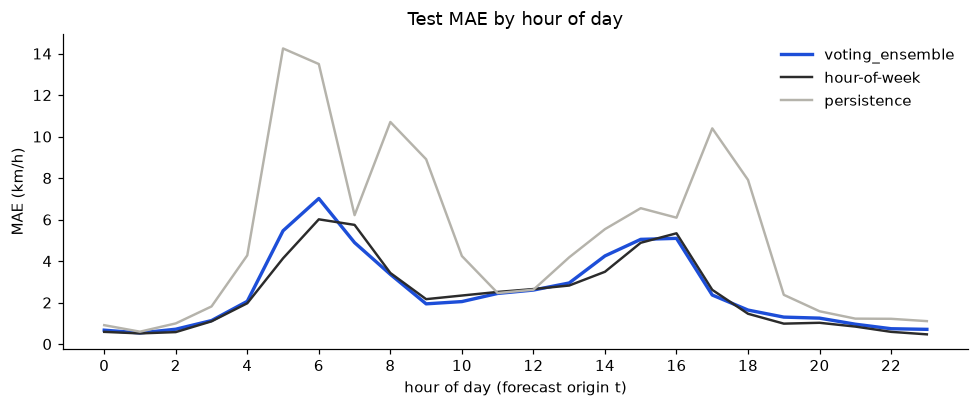

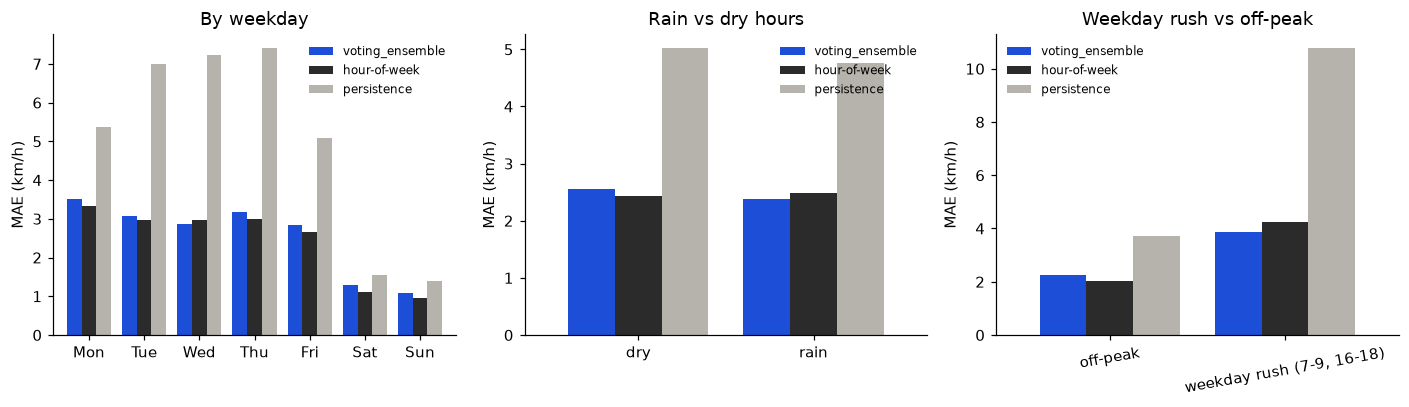

In [3]:
COL = {"MAE_model": "#1d4ed8", "MAE_hour_of_week": "#2b2b2b", "MAE_persistence": "#b5b3ab"}
LAB = {"MAE_model": "voting_ensemble", "MAE_hour_of_week": "hour-of-week", "MAE_persistence": "persistence"}

def bars(ax, t, key, title, rot=0):
    t = t.set_index(key)[list(COL)]
    t.plot.bar(ax=ax, color=list(COL.values()), rot=rot, width=0.8)
    ax.set_title(title); ax.set_ylabel("MAE (km/h)"); ax.set_xlabel(""); ax.legend([LAB[c] for c in t.columns], frameon=False, fontsize=8)

# Figure 1: by segment
fig, ax = plt.subplots(figsize=(9, 3.8)); bars(ax, tabs["segment_id"], "segment_id", "Test MAE by segment", 30)
plt.tight_layout(); plt.savefig("results/errors_by_segment.png", dpi=150); plt.show()

# Figure 2: by hour of day
h = tabs["hour"].set_index("hour")
fig, ax = plt.subplots(figsize=(9, 3.8))
for c in COL: ax.plot(h.index, h[c], color=COL[c], label=LAB[c], lw=2.2 if c == "MAE_model" else 1.6)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hour of day (forecast origin t)"); ax.set_ylabel("MAE (km/h)"); ax.set_title("Test MAE by hour of day"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("results/errors_by_hour.png", dpi=150); plt.show()

# Figure 3: weekday, rain/dry, rush/off-peak
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
d = tabs["dow"].assign(dow=lambda x: x["dow"].map(dict(enumerate(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]))))
bars(ax[0], d, "dow", "By weekday"); bars(ax[1], tabs["rain"], "rain", "Rain vs dry hours"); bars(ax[2], tabs["period"], "period", "Weekday rush vs off-peak", 10)
plt.tight_layout(); plt.savefig("results/errors_by_weekday_rain_rush.png", dpi=150); plt.show()
for f in ["errors_by_segment", "errors_by_hour", "errors_by_weekday_rain_rush"]:
    shutil.copy(f"results/{f}.png", f"docs/img/{f}.png")

In [4]:
s, hh, r, p = tabs["segment_id"], tabs["hour"], tabs["rain"].set_index("rain"), tabs["period"].set_index("period")
rush = p.loc["weekday rush (7-9, 16-18)"]; off = p.loc["off-peak"]
wk = tabs["dow"]
display(Markdown(
 f"**Saw (segment):** model MAE ranges from {s['MAE_model'].min():.2f} (segment {s.loc[s['MAE_model'].idxmin(), 'segment_id']}) to {s['MAE_model'].max():.2f} (segment {s.loc[s['MAE_model'].idxmax(), 'segment_id']}) km/h; "
 f"the model is better than hour-of-week on {int((s['model_minus_how'] < 0).sum())} of {len(s)} segments.\n\n"
 f"**Saw (hour):** the model's MAE peaks at hour {hh.loc[hh['MAE_model'].idxmax(), 'hour']} ({hh['MAE_model'].max():.2f} km/h); it is better than hour-of-week in {int((hh['model_minus_how'] < 0).sum())} of 24 hours.\n\n"
 f"**Saw (rush vs off-peak):** weekday rush hours {rush['MAE_model']:.2f} vs off-peak {off['MAE_model']:.2f} km/h (hour-of-week: {rush['MAE_hour_of_week']:.2f} and {off['MAE_hour_of_week']:.2f}).\n\n"
 f"**Saw (rain):** rainy hours {r.loc['rain', 'MAE_model']:.2f} (n={int(r.loc['rain', 'n'])}) vs dry {r.loc['dry', 'MAE_model']:.2f} km/h (hour-of-week: {r.loc['rain', 'MAE_hour_of_week']:.2f} and {r.loc['dry', 'MAE_hour_of_week']:.2f}).\n\n"
 f"**Saw (weekday):** the model's MAE is highest on {['Mon','Tue','Wed','Thu','Fri','Sat','Sun'][int(wk.loc[wk['MAE_model'].idxmax(), 'dow'])]} at {wk['MAE_model'].max():.2f} km/h."))

**Saw (segment):** model MAE ranges from 1.80 (segment 400100) to 3.12 (segment 402287) km/h; the model is better than hour-of-week on 1 of 8 segments.

**Saw (hour):** the model's MAE peaks at hour 6 (7.01 km/h); it is better than hour-of-week in 8 of 24 hours.

**Saw (rush vs off-peak):** weekday rush hours 3.87 vs off-peak 2.27 km/h (hour-of-week: 4.26 and 2.03).

**Saw (rain):** rainy hours 2.38 (n=192) vs dry 2.56 km/h (hour-of-week: 2.48 and 2.44).

**Saw (weekday):** the model's MAE is highest on Mon at 3.52 km/h.

**Means:** errors concentrate where traffic changes quickly: weekday rush hours are harder than off-peak for both the model and hour-of-week. The model is closer than hour-of-week during weekday rush hours but worse off-peak, so its small overall deficit comes from the quiet hours, where the weekly mean is already near-perfect. Differences between the model and hour-of-week are small compared with the difference between either of them and persistence. The rain sample is small (a few days), so a rain-versus-dry difference should not be over-read.

## 2. Failure cases
Five cases chosen by stated rules, not by hand-picking flattering ones. Each plot shows the speed that actually occurred, the forecast made **two hours earlier**, and the two baselines, plotted at the time being predicted. Explanations are **likely reasons**, not proven ones: the data has no incident log.

case 1 rule: largest single error -> 407157 2017-06-19
case 2 rule: next largest on a different segment-day -> 407176 2017-06-15


C:\Users\shrey\AppData\Local\Temp\ipykernel_13304\2004894656.py:8: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  x = d["timestamp"] + pd.Timedelta("2h")            # time being predicted


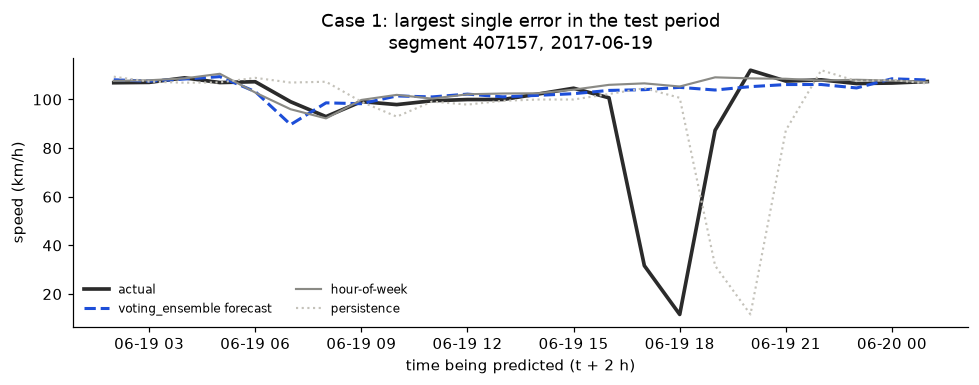

**Saw:** that day the model's MAE is 9.81 km/h (hour-of-week 9.50, persistence 16.27). The largest miss is the forecast issued at 16:00: predicted 105.0, actual 11.6 km/h (error 93.4).

In [5]:
LINES = [("target_2h", "actual", "#2b2b2b", 2.4, "-"), ("pred", "voting_ensemble forecast", "#1d4ed8", 2.0, "--"),
         ("how", "hour-of-week", "#8a8a85", 1.4, "-"), ("persist", "persistence", "#c4c2ba", 1.4, ":")]
cases = []

def plot_case(num, slug, seg, day, title, hours=(0, 24)):
    d = tp[(tp["segment_id"] == seg) & (tp["day"] == pd.Timestamp(day).date())].sort_values("timestamp")
    d = d[(d["timestamp"].dt.hour >= hours[0]) & (d["timestamp"].dt.hour < hours[1])]
    x = d["timestamp"] + pd.Timedelta("2h")            # time being predicted
    fig, ax = plt.subplots(figsize=(9, 3.6))
    for col, lab, c, w, ls in LINES: ax.plot(x, d[col], color=c, lw=w, ls=ls, label=lab)
    ax.set_title(f"Case {num}: {title}\nsegment {seg}, {day}"); ax.set_ylabel("speed (km/h)"); ax.set_xlabel("time being predicted (t + 2 h)")
    ax.legend(frameon=False, fontsize=8, ncol=2, loc="lower left"); plt.tight_layout()
    fn = f"case_{num}_{slug}.png"; plt.savefig(f"results/{fn}", dpi=150); shutil.copy(f"results/{fn}", f"docs/img/{fn}"); plt.show()
    w = tp[(tp["segment_id"] == seg) & (tp["day"] == pd.Timestamp(day).date())]
    row = d.loc[d["abs_err"].idxmax()]
    rec = {"case": num, "slug": slug, "segment": seg, "day": str(day), "day_mae_model": (w["target_2h"] - w["pred"]).abs().mean(),
           "day_mae_how": (w["target_2h"] - w["how"]).abs().mean(), "day_mae_persistence": (w["target_2h"] - w["persist"]).abs().mean(),
           "worst_origin": str(row["timestamp"]), "worst_actual": row["target_2h"], "worst_pred": row["pred"], "worst_abs_err": row["abs_err"], "image": fn}
    cases.append(rec)
    display(Markdown(f"**Saw:** that day the model's MAE is {rec['day_mae_model']:.2f} km/h (hour-of-week {rec['day_mae_how']:.2f}, persistence {rec['day_mae_persistence']:.2f}). "
                     f"The largest miss is the forecast issued at {row['timestamp']:%H:%M}: predicted {row['pred']:.1f}, actual {row['target_2h']:.1f} km/h (error {row['abs_err']:.1f})."))

# Rule for cases 1 and 2: the two largest single-row errors on different segment-days
top = tp.sort_values("abs_err", ascending=False)
c1 = top.iloc[0]
c2 = top[(top["segment_id"] != c1["segment_id"]) | (top["day"] != c1["day"])].iloc[0]
print("case 1 rule: largest single error ->", c1["segment_id"], c1["day"])
print("case 2 rule: next largest on a different segment-day ->", c2["segment_id"], c2["day"])
plot_case(1, "sudden_drop", c1["segment_id"], c1["day"], "largest single error in the test period")

**Means (case 1):** speed was normal, then fell within two hours to a very low value for about two hours and recovered. Neither the model nor the baselines can see this coming from past speeds, weather or the calendar. This looks like a one-off event such as a crash or lane closure (a likely reason, not confirmed). Persistence is even worse, because it is wrong both when the drop starts and when it ends.

C:\Users\shrey\AppData\Local\Temp\ipykernel_13304\2004894656.py:8: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  x = d["timestamp"] + pd.Timedelta("2h")            # time being predicted


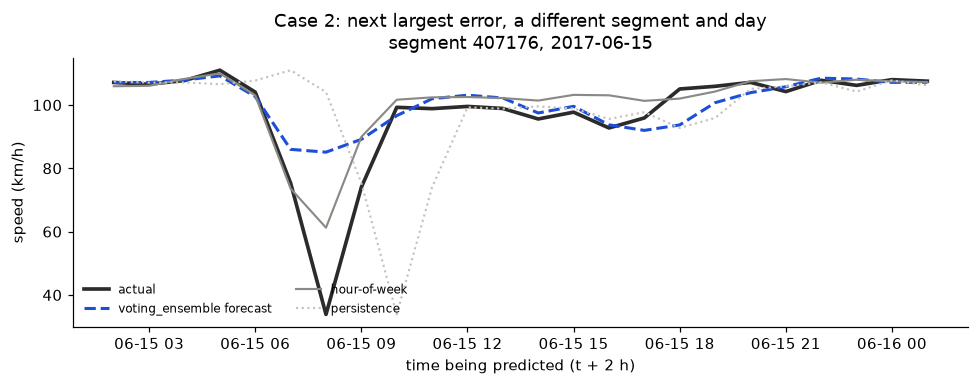

**Saw:** that day the model's MAE is 5.31 km/h (hour-of-week 4.20, persistence 10.30). The largest miss is the forecast issued at 06:00: predicted 85.1, actual 33.8 km/h (error 51.2).

In [6]:
plot_case(2, "morning_dip", c2["segment_id"], c2["day"], "next largest error, a different segment and day")

**Means (case 2):** a brief early-morning dip in speed, again outside the usual pattern. The weekly mean and the model both hedge (predicting a partial slowdown) at the hours around it, which costs error before and after the real dip. A likely reason is a short incident; the data cannot confirm it.

case 3 rule: the holiday in the test period -> 2017-05-29 | segment with the largest model error that day: 407176


C:\Users\shrey\AppData\Local\Temp\ipykernel_13304\2004894656.py:8: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  x = d["timestamp"] + pd.Timedelta("2h")            # time being predicted


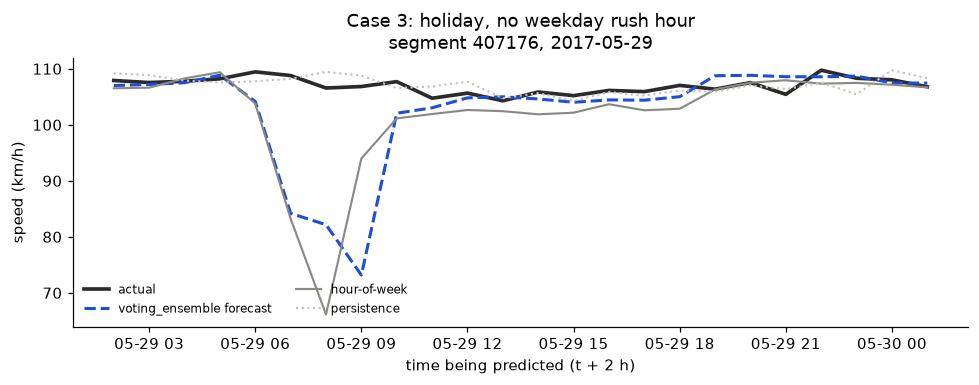

**Saw:** that day the model's MAE is 4.85 km/h (hour-of-week 5.27, persistence 1.23). The largest miss is the forecast issued at 07:00: predicted 73.2, actual 106.8 km/h (error 33.7).

In [7]:
hol = tp[tp["is_holiday"] == 1]
hday = hol["day"].iloc[0]
hs = hol[hol["day"] == hday].groupby("segment_id")["abs_err"].mean().idxmax()
print("case 3 rule: the holiday in the test period ->", hday, "| segment with the largest model error that day:", hs)
plot_case(3, "holiday", hs, hday, "holiday, no weekday rush hour")

**Means (case 3):** on a public holiday traffic stays at free-flow speed through the morning, but both forecasts expect the weekday slowdown. The model is closer than hour-of-week because it has a holiday flag, yet it still predicts a slowdown that did not happen. Persistence has the lowest error that day, because nothing changes. Only one holiday falls in the test period, so this is one example, not a rate.

case 4 rule: longest run of identical hourly speed on segment 400100 in the test period -> 2017-05-30 12:00:00 to 2017-05-30 23:00:00 (12 h at 107.7 km/h)


C:\Users\shrey\AppData\Local\Temp\ipykernel_13304\2004894656.py:8: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  x = d["timestamp"] + pd.Timedelta("2h")            # time being predicted


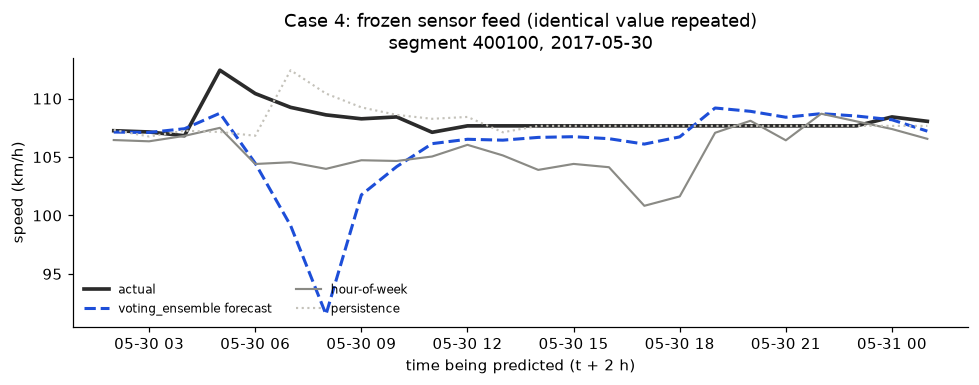

**Saw:** that day the model's MAE is 2.65 km/h (hour-of-week 2.71, persistence 0.81). The largest miss is the forecast issued at 06:00: predicted 91.5, actual 108.6 km/h (error 17.1).

In [8]:
flat = tp[tp["segment_id"] == "400100"].sort_values("timestamp")
grp = flat["speed_kmh"].ne(flat["speed_kmh"].shift()).cumsum()
runs = flat.groupby(grp).agg(start=("timestamp", "min"), end=("timestamp", "max"), n=("speed_kmh", "size"), kmh=("speed_kmh", "first"))
longest = runs.loc[runs["n"].idxmax()]
print("case 4 rule: longest run of identical hourly speed on segment 400100 in the test period ->", longest["start"], "to", longest["end"], f"({int(longest['n'])} h at {longest['kmh']:.1f} km/h)")
plot_case(4, "frozen_feed", "400100", longest["start"].date(), "frozen sensor feed (identical value repeated)")

**Means (case 4):** the sensor repeats one value for hours. Inside the frozen stretch the error looks small and persistence looks nearly perfect, but only because the data is frozen, not because the forecast is good; the largest miss on this day comes from the real hours just before the freeze. Scores on this segment are flattering and say little about real traffic. Segment 400100 was kept in the study and listed as a limitation.

case 5 rule: the day with the most rainy segment-hours -> 2017-06-09 (48 segment-hours) | segment with the largest model error that day: 402287


C:\Users\shrey\AppData\Local\Temp\ipykernel_13304\2004894656.py:8: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  x = d["timestamp"] + pd.Timedelta("2h")            # time being predicted


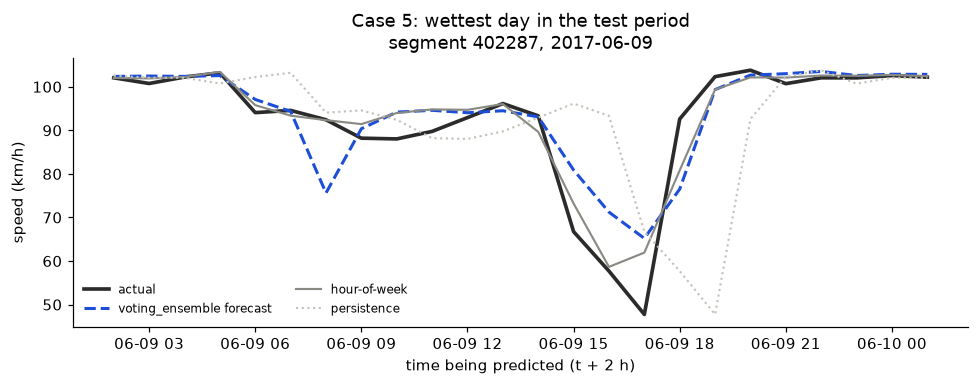

**Saw:** that day the model's MAE is 4.57 km/h (hour-of-week 2.71, persistence 9.87). The largest miss is the forecast issued at 15:00: predicted 65.2, actual 47.7 km/h (error 17.5).

In [9]:
rain_days = tp[tp["rain"] == "rain"].groupby("day").size().sort_values(ascending=False)
rday = rain_days.index[0]
rs = tp[(tp["day"] == rday)].groupby("segment_id")["abs_err"].mean().idxmax()
print("case 5 rule: the day with the most rainy segment-hours ->", rday, f"({rain_days.iloc[0]} segment-hours) | segment with the largest model error that day:", rs)
plot_case(5, "rain_day", rs, rday, "wettest day in the test period")

**Means (case 5):** rain was a suspect for slow, unpredictable traffic, so the wettest day is shown. On this day the model does worse than hour-of-week on the chosen segment (see the numbers above), with a late-afternoon slowdown that was larger than forecast. But the breakdown in section 1 shows rainy hours overall are not clearly worse than dry hours. With only a few wet days, rain effects cannot be separated from other things that happen on the same days.

In [10]:
cs = pd.DataFrame(cases).round(2); cs.to_csv("results/error_cases.csv", index=False); cs

,case,slug,segment,day,day_mae_model,day_mae_how,day_mae_persistence,worst_origin,worst_actual,worst_pred,worst_abs_err,image
0,1,sudden_drop,407157,2017-06-19,9.81,9.50,16.27,2017-06-19 16:00:00,11.61,104.97,93.36,case_1_sudden_drop.png
1,2,morning_dip,407176,2017-06-15,5.31,4.20,10.30,2017-06-15 06:00:00,33.85,85.10,51.25,case_2_morning_dip.png
2,3,holiday,407176,2017-05-29,4.85,5.27,1.23,2017-05-29 07:00:00,106.83,73.17,33.66,case_3_holiday.png
3,4,frozen_feed,400100,2017-05-30,2.65,2.71,0.81,2017-05-30 06:00:00,108.60,91.53,17.07,case_4_frozen_feed.png
4,5,rain_day,402287,2017-06-09,4.57,2.71,9.87,2017-06-09 15:00:00,47.74,65.21,17.47,case_5_rain_day.png


## 3. Limitations (from these results)
1. **One network, one half-year.** Eight segments on Bay Area freeways, January to June 2017. Nothing here says how the model behaves elsewhere or in other seasons.
2. **Sensor quality.** Zero readings are treated as missing, and one network-wide feed outage was seen in the raw data. Segment 400100 repeats values for many hours on several days (case 4); it was kept and flagged, not repaired.
3. **No incident, roadworks or event data.** The biggest errors (cases 1 and 2) look like unforecastable events. No model built on these inputs can anticipate them.
4. **Weather is observed at time t,** not forecast, so the weather features are easier than they would be in real use.
5. **Distribution shift.** Test hours are the last five weeks of the series (late May to June). Patterns change with seasons, school terms and roadworks.
6. **Association, not causation.** The model finds patterns that go with speed; it does not show what causes slowdowns.
7. **The test run was not sealed.** It was run earlier than planned (see the disclosure in notebook 03). No change was made afterwards, but the order of events is a limitation of the process.
8. **No trained model beat hour-of-week** on validation or on test. The weekly mean is a strong baseline at this horizon.